In [1]:
import cosmic
from cosmic.output import load_initC
import h5py as h5
import os
import pandas as pd
import astropy.units as u
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from importlib import reload
from astropy.coordinates import SkyCoord
import seaborn as sns
from copy import copy

import legwork as lw
import gala.potential as gp
import cogsworth

import sys
sys.path.append("../helpers")

import detections
import const
import plotting
import uncertainties as unc

plt.rc('font', family='serif')
plt.rcParams['text.usetex'] = False
fs = 24

# update various fontsizes to match
params = {'figure.figsize': (12, 8),
          'legend.fontsize': 0.7*fs,
          'legend.title_fontsize': 0.8*fs,
          'axes.labelsize': fs,
          'xtick.labelsize': 0.9 * fs,
          'ytick.labelsize': 0.9 * fs,
          'axes.linewidth': 1.1,
          'xtick.major.size': 7,
          'xtick.minor.size': 4,
          'ytick.major.size': 7,
          'ytick.minor.size': 4}
plt.rcParams.update(params)

%config InlineBackend.figure_format = 'retina'

# Load data

In [2]:
dco_types = const.DCO_TYPES.copy()

In [3]:
pops = {
    dco_type: cogsworth.pop.load(f"/mnt/ceph/users/twagg/lisa-dcos/fiducial/{dco_type}_pessimistic_in_band.h5") for dco_type in const.DCO_TYPES
}

detectable_pops = {}
for dco_type in const.DCO_TYPES:
    pop = pops[dco_type]
    print(dco_type)
    pop.final_pos, pop.final_vel
    
    mask = (
        (pops[dco_type].bpp["snr_lisa_8yr_final_pos"] > 12)
        | (pops[dco_type].bpp["snr_lisa_8yr_initial_pos"] > 12)
        | (pops[dco_type].bpp["snr_decigo_8yr_final_pos"] > 12)
        | (pops[dco_type].bpp["snr_decigo_8yr_initial_pos"] > 12)
    )
    detectable_pops[dco_type] = pops[dco_type][mask]

lisa_pops = {dco_type: pops[dco_type][pops[dco_type].bpp["snr_lisa_8yr_final_pos"] > 12] for dco_type in const.DCO_TYPES}

cogsworth warning: You've just masked a population that wasn't fully loaded from a file. This means that the masked population won't have access to the parts that were not loaded. If you don't need the missing parts then this is fine, for reference those are: ['orbits'].


BHBH


cogsworth warning: You've just masked a population that wasn't fully loaded from a file. This means that the masked population won't have access to the parts that were not loaded. If you don't need the missing parts then this is fine, for reference those are: ['orbits'].


BHNS


cogsworth warning: You've just masked a population that wasn't fully loaded from a file. This means that the masked population won't have access to the parts that were not loaded. If you don't need the missing parts then this is fine, for reference those are: ['orbits'].


...

cogsworth warning: You've just masked a population that wasn't fully loaded from a file. This means that the masked population won't have access to the parts that were not loaded. If you don't need the missing parts then this is fine, for reference those are: ['orbits'].


NSNS


cogsworth warning: You've just masked a population that wasn't fully loaded from a file. This means that the masked population won't have access to the parts that were not loaded. If you don't need the missing parts then this is fine, for reference those are: ['orbits'].


NSWD


cogsworth warning: You've just masked a population that wasn't fully loaded from a file. This means that the masked population won't have access to the parts that were not loaded. If you don't need the missing parts then this is fine, for reference those are: ['orbits'].
cogsworth warning: You've just masked a population that wasn't fully loaded from a file. This means that the masked population won't have access to the parts that were not loaded. If you don't need the missing parts then this is fine, for reference those are: ['orbits'].
cogsworth warning: You've just masked a population that wasn't fully loaded from a file. This means that the masked population won't have access to the parts that were not loaded. If you don't need the missing parts then this is fine, for reference those are: ['orbits'].
cogsworth warning: You've just masked a population that wasn't fully loaded from a file. This means that the masked population won't have access to the parts that were not loaded. If y

In [54]:
rerun_pops = {}
rerun_weights = {}
for dco_type in const.DCO_TYPES:
    rand_sample = np.random.choice(lisa_pops[dco_type].initC.index, size=10_000, replace=False)
    rerun_pops[dco_type] = lisa_pops[dco_type][lisa_pops[dco_type].initC.index.isin(rand_sample)]
    rerun_weights[dco_type] = rerun_pops[dco_type].bpp["weights"].values

In [62]:
bpp_cols = ['tphys', 'mass_1', 'mass_2', 'kstar_1', 'kstar_2',
               'sep', 'porb', 'ecc', 'evol_type', 'RRLO_1', 'RRLO_2', 'SN_1', 'SN_2']

In [ ]:
for dco_type in const.DCO_TYPES:
    print(f"Performing stellar evolution for {dco_type}...")
    rerun_pops[dco_type].processes = 32
    rerun_pops[dco_type].bpp_columns = bpp_cols
    rerun_pops[dco_type].SSE_settings = {}
    rerun_pops[dco_type].BSE_settings = {}
    rerun_pops[dco_type].perform_stellar_evolution()

In [ ]:
for dco_type in const.DCO_TYPES:
    print(dco_type)

    rerun_pops[dco_type].bpp["row_num"] = np.arange(len(rerun_pops[dco_type].bpp))

    # create a new column called "experienced_ce_already" which is True if the binary has experienced a CE event before this row
    # find every row where evol_type is 7 (ce starts) and mark all subsequent rows with the same bin_num as having experienced a CE event
    rerun_pops[dco_type].bpp["experienced_ce_already"] = False
    ce_start_rows = rerun_pops[dco_type].bpp[rerun_pops[dco_type].bpp["evol_type"] == 7]
    for _, row in ce_start_rows.iterrows():
        rerun_pops[dco_type].bpp.loc[
            (rerun_pops[dco_type].bpp["bin_num"] == row["bin_num"]) &
            (rerun_pops[dco_type].bpp["row_num"] > row["row_num"]),
            "experienced_ce_already"
        ] = True

In [153]:
from scipy.stats import lognorm, maxwell
# lognormal distribution with mu=5.60 and sigma=0.68
print("Median of lognormal distribution:", np.median(lognorm(s=0.68, scale=np.exp(5.60)).rvs(1_000_000)))
# maxwellian with 265 km/s
print("Median of maxwellian distribution:", np.median(maxwell(scale=265).rvs(1_000_000)))

Median of lognormal distribution: 270.486803032597
Median of maxwellian distribution: 407.88659800437017


BHBH
  Separation at first SN 901.16
  Separation at last SN 16.59
  Median kick velocity at first SN 0.8
  Median kick velocity at last SN 58.9
  20.24% of BHBH binaries have experienced a CE event before the first SN.
  93.33% of BHBH binaries have experienced a CE event before the last SN.
SN_1  SN_2
1     1       9982
      0         14
6     1          4
Name: count, dtype: int64

BHNS
  Separation at first SN 439.88
  Separation at last SN 8.07
  Median kick velocity at first SN 9.3
  Median kick velocity at last SN 128.1
  40.13% of BHNS binaries have experienced a CE event before the first SN.
  83.59% of BHNS binaries have experienced a CE event before the last SN.
SN_1  SN_2
1     1       9927
      0         70
      2          3
Name: count, dtype: int64

BHWD
  Separation at last SN 71.16
  Median kick velocity at last SN 47.9
  99.86% of BHWD binaries have experienced a CE event before the last SN.
SN_1  SN_2
1     0       10000
Name: count, dtype: int64

NSNS
  Separatio

[Text(0.5, 0, 'Separation at final SN, $\\log_{10}(a/R_\\odot)$'),
 Text(0, 0.5, 'Probability density')]

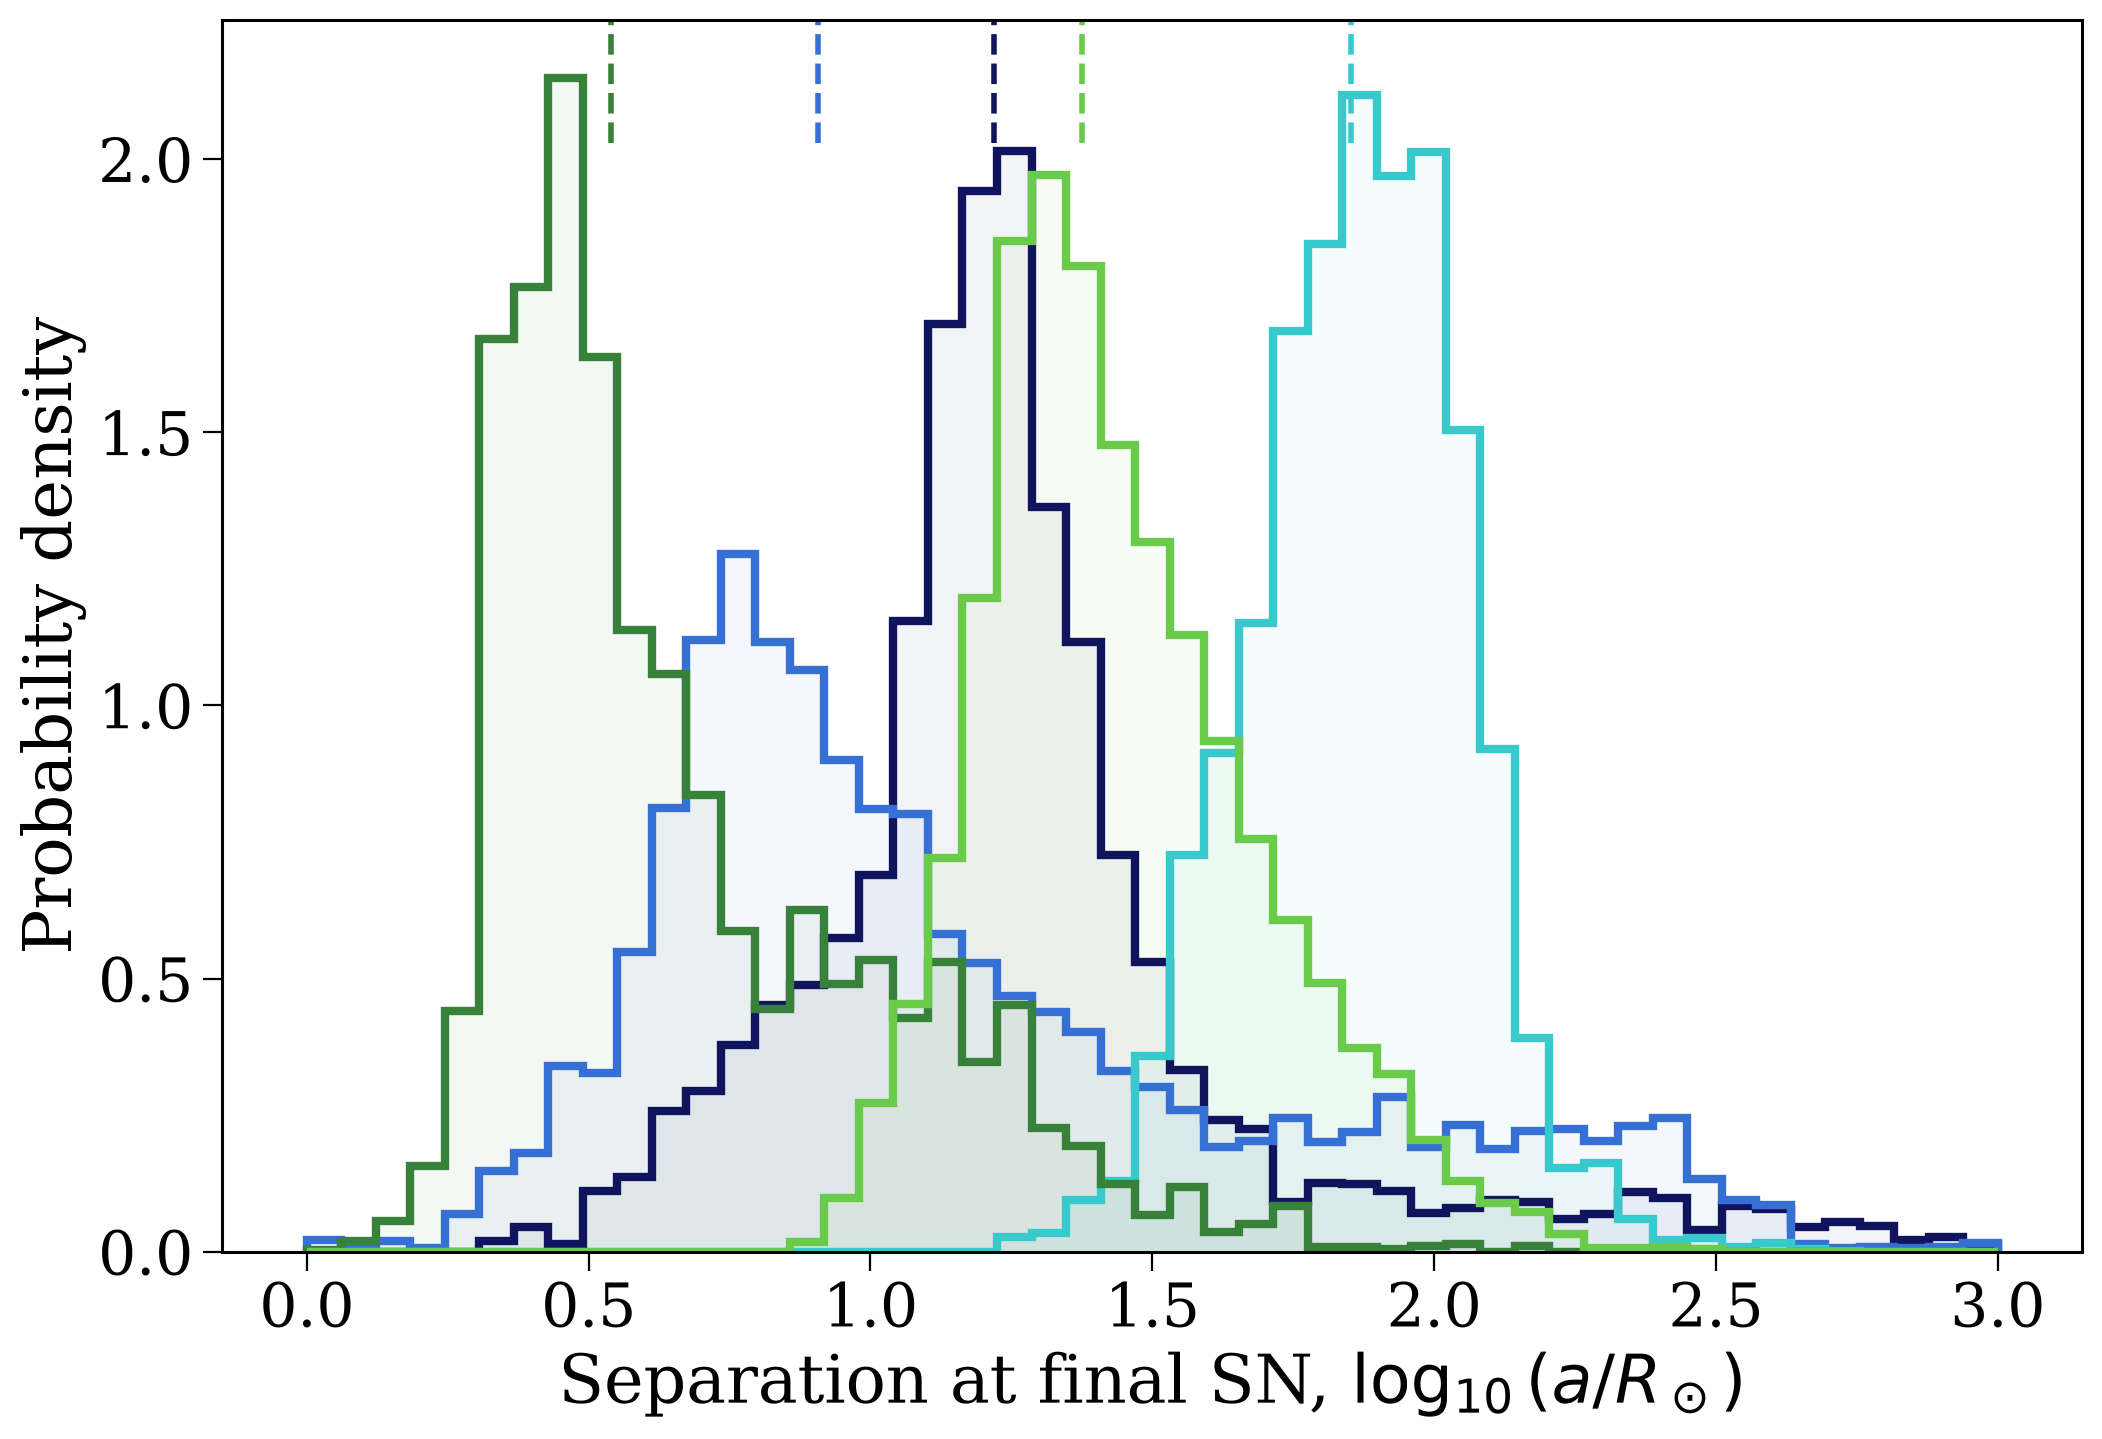

In [176]:
fig, ax = plt.subplots()

for dco_type in const.DCO_TYPES:
    print(dco_type)

    sn_rows = rerun_pops[dco_type].bpp[rerun_pops[dco_type].bpp["evol_type"].isin([15, 16])]
    first_sn_rows = sn_rows.drop_duplicates(subset="bin_num", keep="first")
    last_sn_rows = sn_rows.drop_duplicates(subset="bin_num", keep="last")

    first_post_sn_rows = rerun_pops[dco_type].bpp[rerun_pops[dco_type].bpp["row_num"].isin(first_sn_rows["row_num"] + 1)]
    last_post_sn_rows = rerun_pops[dco_type].bpp[rerun_pops[dco_type].bpp["row_num"].isin(last_sn_rows["row_num"] + 1)]

    plotting.nice_transparent_hist(
        ax, np.log10(last_sn_rows["sep"]), bins=np.linspace(0, 3, 50), weights=rerun_weights[dco_type],
        label=f"Last SN ({dco_type})", colour=const.DCO_COLOURS[dco_type], density=True, alpha=0.05, lw=3
    )
    # ax.hist(
    #     np.log10(last_sn_rows["sep"]), bins=np.linspace(0, 3, 70), weights=rerun_weights[dco_type],
    #     histtype="step", label="Last SN", color=const.DCO_COLOURS[dco_type], lw=2, density=True
    # )
    ax.axvline(
        np.median(np.log10(last_sn_rows["sep"])), 0.9, 1.0, color=const.DCO_COLOURS[dco_type], ls="--", lw=2
    )

    kicks = rerun_pops[dco_type].kick_info.sort_values(by="tphys")
    kicks = kicks[kicks["star"] != 0]
    med_kick_1 = np.median(np.linalg.norm(kicks.drop_duplicates(subset="bin_num", keep="first")[["delta_vsysx_1", "delta_vsysy_1", "delta_vsysz_1"]], axis=1))
    med_kick_2 = np.median(np.linalg.norm(kicks.drop_duplicates(subset="bin_num", keep="last")[["delta_vsysx_1", "delta_vsysy_1", "delta_vsysz_1"]], axis=1))

    if "WD" not in dco_type:
        print("  Separation at first SN", np.median(first_sn_rows["sep"]).round(2))
    print("  Separation at last SN", np.median(last_sn_rows["sep"]).round(2))
    if "WD" not in dco_type:
        print("  Median kick velocity at first SN", med_kick_1.round(1))
    print("  Median kick velocity at last SN", med_kick_2.round(1))
    if "WD" not in dco_type:
        print(f"  {np.sum(rerun_weights[dco_type][first_sn_rows["experienced_ce_already"]]) / np.sum(rerun_weights[dco_type]):.2%} of {dco_type} binaries have experienced a CE event before the first SN.")
    print(f"  {np.sum(rerun_weights[dco_type][last_sn_rows["experienced_ce_already"]]) / np.sum(rerun_weights[dco_type]):.2%} of {dco_type} binaries have experienced a CE event before the last SN.")
    print(last_sn_rows[["SN_1", "SN_2"]].value_counts())
    print()

ax.set(
    xlabel=r"Separation at final SN, $\log_{10}(a/R_\odot)$",
    ylabel="Probability density",
)

BHBH
BHNS
BHWD
NSNS
NSWD


/mnt/home/twagg/miniforge3/envs/cogsworth/lib/python3.12/site-packages/numpy/lib/_histograms_impl.py:901: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges
/mnt/home/twagg/miniforge3/envs/cogsworth/lib/python3.12/site-packages/numpy/lib/_histograms_impl.py:901: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges


[Text(0.5, 0, 'Mass of newly formed BHs, $M_\\odot$'),
 Text(0, 0.5, 'Probability density')]

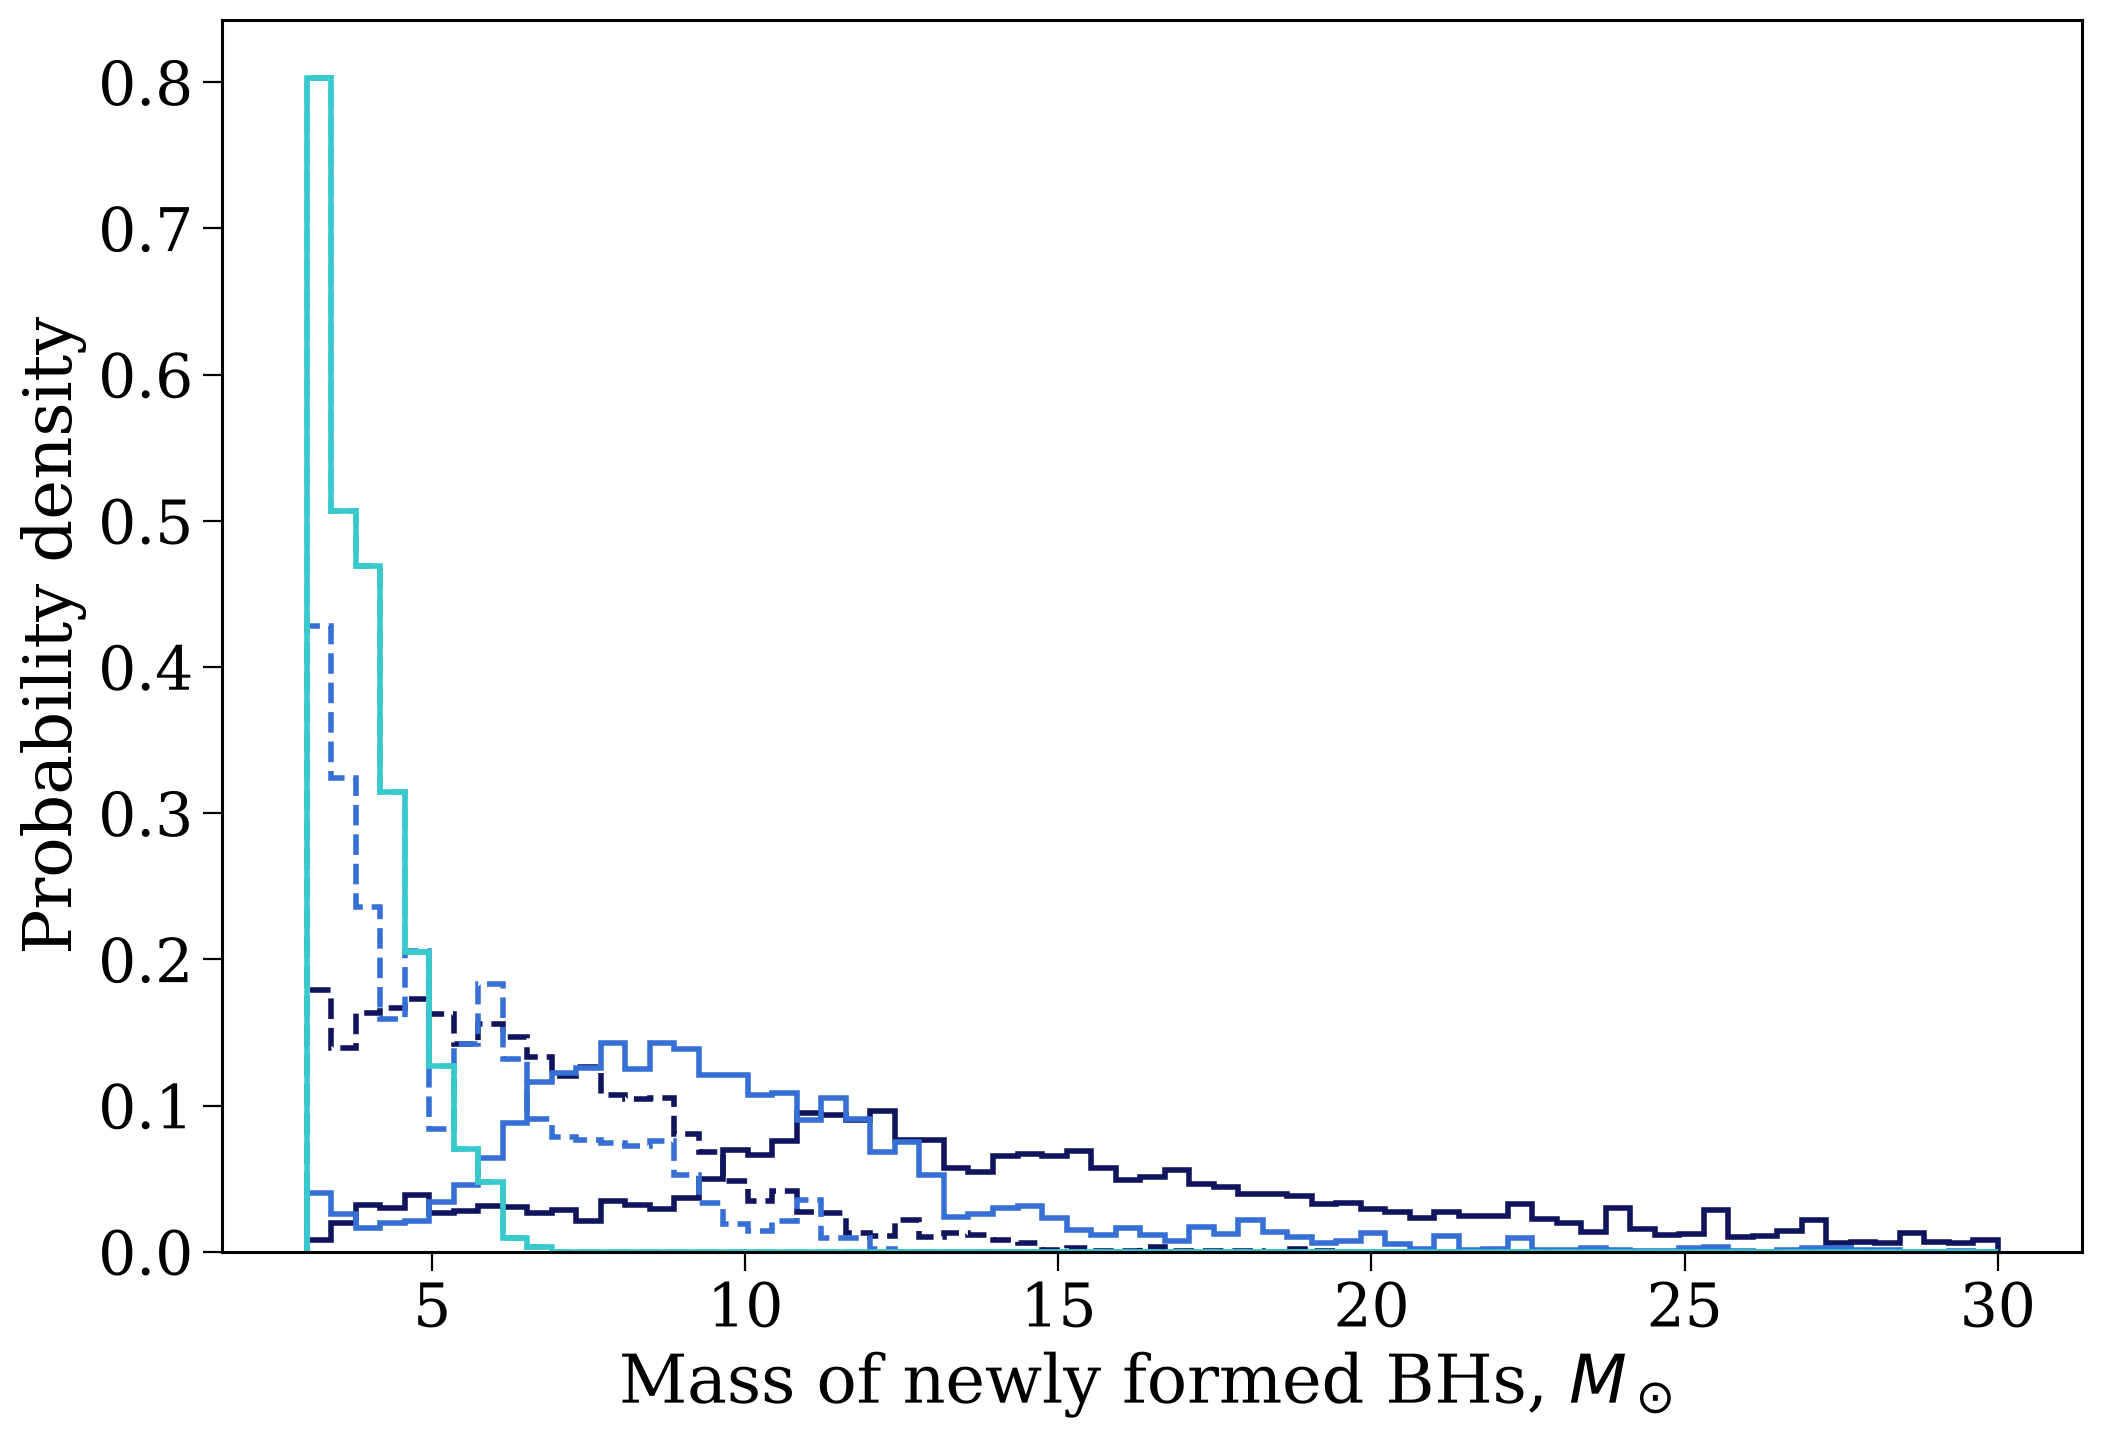

In [82]:
fig, ax = plt.subplots()

for dco_type in const.DCO_TYPES:
    print(dco_type)

    rerun_pops[dco_type].bpp["row_num"] = np.arange(len(rerun_pops[dco_type].bpp))

    sn_rows = rerun_pops[dco_type].bpp[rerun_pops[dco_type].bpp["evol_type"].isin([15, 16])]
    first_sn_rows = sn_rows.drop_duplicates(subset="bin_num", keep="first")
    last_sn_rows = sn_rows.drop_duplicates(subset="bin_num", keep="last")

    first_post_sn_rows = rerun_pops[dco_type].bpp[rerun_pops[dco_type].bpp["row_num"].isin(first_sn_rows["row_num"] + 1)]
    last_post_sn_rows = rerun_pops[dco_type].bpp[rerun_pops[dco_type].bpp["row_num"].isin(last_sn_rows["row_num"] + 1)]

    # find masses of newly formed BHs (systems that have kstar_1 or kstar_2 == 14 in the post SN rows and NOT in the pre SN rows)
    first_sn_new_bh_masses = np.concatenate([
        first_post_sn_rows.loc[(first_post_sn_rows["kstar_1"] == 14) & (first_sn_rows["kstar_1"] != 14), "mass_1"].values,
        first_post_sn_rows.loc[(first_post_sn_rows["kstar_2"] == 14) & (first_sn_rows["kstar_2"] != 14), "mass_2"].values
    ])
    weights_FSNNBHMs = np.concatenate([
        rerun_weights[dco_type][(first_post_sn_rows["kstar_1"] == 14) & (first_sn_rows["kstar_1"] != 14)],
        rerun_weights[dco_type][(first_post_sn_rows["kstar_2"] == 14) & (first_sn_rows["kstar_2"] != 14)]
    ])
    last_sn_new_bh_masses = np.concatenate([
        last_post_sn_rows.loc[(last_post_sn_rows["kstar_1"] == 14) & (last_sn_rows["kstar_1"] != 14), "mass_1"].values,
        last_post_sn_rows.loc[(last_post_sn_rows["kstar_2"] == 14) & (last_sn_rows["kstar_2"] != 14), "mass_2"].values
    ])
    weights_LSNNBHMs = np.concatenate([
        rerun_weights[dco_type][(last_post_sn_rows["kstar_1"] == 14) & (last_sn_rows["kstar_1"] != 14)],
        rerun_weights[dco_type][(last_post_sn_rows["kstar_2"] == 14) & (last_sn_rows["kstar_2"] != 14)]
    ])

    ax.hist(
        first_sn_new_bh_masses, bins=np.linspace(3, 30, 70), weights=weights_FSNNBHMs,
        histtype="step", label="First SN", color=const.DCO_COLOURS[dco_type], lw=2, density=True
    )
    ax.hist(
        last_sn_new_bh_masses, bins=np.linspace(3, 30, 70), weights=weights_LSNNBHMs,
        histtype="step", label="Last SN", color=const.DCO_COLOURS[dco_type], lw=2, ls="--", density=True
    )

ax.set(
    xlabel=r"Mass of newly formed BHs, $M_\odot$",
    ylabel="Probability density",
)